# Step 18 — When does weighting the experts start to matter?

Notebooks 17 and 18 found that weighting experts never beats weighting them equally: three
parameterisations (softmax, independent sigmoid, Gumbel), four datasets, five seeds, all null.

The motivating intuition was sound, though: mean-pooling treats an expert that cannot see the
columns a row depends on exactly like one that can. **The reason it failed is that at
`feature_frac=0.7` there are no blind experts to down-weight.**

| Dataset | Features | Per expert | Pairwise overlap | Each feature seen by |
|---|---|---|---|---|
| California | 8 | 6 | **75%** | 12 of 16 experts |
| Higgs Small | 28 | 20 | **71%** | 11 of 16 experts |

Any two experts share about three quarters of their columns, and every feature reaches most of
the ensemble. There are not informed and blind experts — there are sixteen slightly-cropped views
of nearly the same data. So the mechanism was tested in a regime where the problem it solves
barely exists.

### The question this notebook asks

Does the advantage of weighting appear once the experts really are blind?

`feature_frac` is swept over four values, which produces a genuine blindness gradient:

| frac | CA feats/expert | CA overlap | HI feats/expert | HI overlap |
|---|---|---|---|---|
| 0.2 | 2 of 8 | **28%** | 6 of 28 | **22%** |
| 0.4 | 3 of 8 | 37% | 11 of 28 | 38% |
| 0.7 | 6 of 8 | 75% | 20 of 28 | 71% |
| 1.0 | 8 of 8 | **100%** | 28 of 28 | **100%** |

At `frac=0.2` on California an expert sees **two features**, and some features reach only 1 of the
16 experts. That is blindness. At `frac=1.0` there is no bagging at all and every expert sees
everything — the natural zero-blindness endpoint.

### What is measured

**The gap between the two arms at each frac — not the raw scores.** Lower `feature_frac` will
almost certainly hurt absolute accuracy, and notebook 16 already showed feature bagging is not
load-bearing for expert diversity. Reading the raw numbers would just rediscover that starving
experts of features makes them worse. The quantity of interest is
`conf_dynamic - conf_uniform` at each frac, sign-corrected so positive always means weighting won.

### Pre-registered decision rule (fixed before running)

> **Mechanism is real, 0.7 is simply outside its regime** if `conf_dynamic` beats `conf_uniform`
> (paired t-test, p<0.05) at `frac <= 0.4` on both datasets, *and* the gap is larger at low frac
> than at 0.7 (negative Spearman correlation between frac and gap, p<0.05).
>
> **Weighting does not help regardless of blindness** if the gap is indistinguishable from zero at
> every frac. Notebook 18's conclusion then generalises rather than being configuration-specific.
>
> Anything in between is reported as partial, with the trend shown.

## 0. Setup

In [1]:
import os, sys, time, json, subprocess, warnings, itertools
warnings.filterwarnings("ignore")
PROJECT_DIR = os.getcwd(); sys.path.insert(0, PROJECT_DIR)
os.environ["PYTHONPATH"] = PROJECT_DIR + os.pathsep + os.environ.get("PYTHONPATH", "")

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from scipy import stats
from joblib import Parallel, delayed

import benchmarks, benchmarks_rtdl
from training import get_device
from weak_learners import WeakLearnerConfig, WeakLearnerEnsemble
from attention import AttentionConfig
from embeddings import EmbeddingConfig
from model import make_arm
from results import save_report
from plotting import apply_style, role_color, INK, INK_SECONDARY, _strip_axes

DEVICE = get_device()

# Smoke test:
#   SRP_SUBSAMPLE=1500 SRP_SEEDS=2 SRP_EPOCHS=3 SRP_PATIENCE=2 SRP_FRACS=0.2,1.0 jupyter nbconvert ...
KEYS      = os.environ.get("SRP_KEYS", "CA,HI").split(",")
ARMS      = os.environ.get("SRP_ARMS", "conf_uniform,conf_dynamic").split(",")
FRACS     = [float(f) for f in os.environ.get("SRP_FRACS", "0.2,0.4,0.7,1.0").split(",")]
SEEDS     = tuple(range(int(os.environ.get("SRP_SEEDS", "5"))))
EPOCHS    = int(os.environ.get("SRP_EPOCHS", "400"))
PATIENCE  = int(os.environ.get("SRP_PATIENCE", "20"))
SUBSAMPLE = int(os.environ.get("SRP_SUBSAMPLE", "0")) or None

# feature_frac is the swept axis, so it is NOT in ENS_KW.
ENS_KW   = dict(num_learners=16, hidden_dim=16, embed_dim=32, depth=1, dropout=0.1)
ATT_KW   = dict(embed_dim=32, num_heads=4, attn_depth=2, ff_mult=4, dropout=0.1, need_weights=False)
EMB_KW   = dict(mode="periodic", d_embedding=8, n_frequencies=16, sigma=0.1)
TRAIN_KW = dict(epochs=EPOCHS, patience=PATIENCE, lr=1e-3, batch_size=512, weight_decay=1e-4)

LOADER = {"CA": benchmarks_rtdl, "AD": benchmarks_rtdl, "JA": benchmarks_rtdl,
          "HI": benchmarks, "SA": benchmarks, "FB": benchmarks}
BASE, WEIGHTED = "conf_uniform", "conf_dynamic"
ARM_LABEL = {"conf_uniform": "uniform (1/K)", "conf_dynamic": "learned per-row weights"}

THREADS_PER_JOB = 2
N_JOBS = int(os.environ.get("SRP_JOBS", "0")) or (
    3 if DEVICE.type == "cuda" else max(1, min(8, (os.cpu_count() or 2) // THREADS_PER_JOB)))

RUN_DIR = os.path.join(PROJECT_DIR, "runs"); os.makedirs(RUN_DIR, exist_ok=True)
STAMP = time.strftime("%Y%m%d_%H%M%S")
LOG_PATH = os.path.join(RUN_DIR, f"19_progress_{STAMP}.log")
_latest = os.path.join(RUN_DIR, "19_progress.log")
if os.path.islink(_latest) or os.path.exists(_latest):
    os.remove(_latest)
os.symlink(os.path.basename(LOG_PATH), _latest)
REPORT_DIR = os.path.join(PROJECT_DIR, "results", "feature_frac_sweep")
FIG_DIR = os.path.join(os.path.dirname(PROJECT_DIR), "figures")

def log(msg):
    print(msg, flush=True)
    with open(LOG_PATH, "a") as f: f.write(time.strftime("%H:%M:%S ") + msg + "\n")
def show(df, fmt=None, style=None):
    try:
        s = df.style.format(fmt or {}, na_rep="—"); display(style(s) if style else s)
    except (AttributeError, ImportError):
        display(df.round(4))

apply_style()
gpu = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU only"
log(f"device: {DEVICE} ({gpu}) | keys={KEYS} | fracs={FRACS} | arms={ARMS} | seeds={len(SEEDS)} | "
    f"epochs<={EPOCHS} patience={PATIENCE} | {N_JOBS} workers")
log(f"{len(KEYS)*len(FRACS)*len(ARMS)*len(SEEDS)} runs total")
if SUBSAMPLE:
    log(f"SMOKE TEST: {SUBSAMPLE} rows per split -- numbers below are NOT real results.")

device: cuda (NVIDIA RTX A4000) | keys=['CA', 'HI'] | fracs=[0.2, 0.4, 0.7, 1.0] | arms=['conf_uniform', 'conf_dynamic'] | seeds=5 | epochs<=400 patience=20 | 3 workers


80 runs total


## 1. Self-tests first

In [2]:
# model.py asserts PASS/FAIL; weak_learners.py's __main__ is a demo that only has to RUN
# (its geometry is asserted directly in section 3 instead).
for module, expect_pass in (("model.py", True), ("weak_learners.py", False)):
    out = subprocess.run([sys.executable, module], cwd=PROJECT_DIR, capture_output=True, text=True)
    text = out.stdout + out.stderr
    n_pass, n_fail = text.count("PASS"), text.count("FAIL")
    log(f"  {module:18s} exit {out.returncode}, {n_pass} PASS, {n_fail} FAIL")
    assert out.returncode == 0, text[-3000:]
    assert n_fail == 0, text[-3000:]
    if expect_pass:
        assert n_pass > 0, text[-3000:]
log("self-tests passed")

  model.py           exit 0, 23 PASS, 0 FAIL


  weak_learners.py   exit 0, 0 PASS, 0 FAIL


self-tests passed


## 2. Data

In [3]:
DATA, ARRAYS = {}, {}
for k in KEYS:
    d = LOADER[k].load_benchmark(k)
    assert d.task != "multiclass", f"{k} is multiclass; pool_level='output' needs a scalar per expert"
    a = d.arrays()
    if SUBSAMPLE:
        n = SUBSAMPLE
        a = {"Xtr": a["Xtr"][:n], "ytr": a["ytr"][:n], "Xva": a["Xva"][:n // 2], "yva": a["yva"][:n // 2],
             "Xte": a["Xte"][:n], "yte": a["yte"][:n]}
    DATA[k], ARRAYS[k] = d, a
    log(d.summary())
HIB = {k: LOADER[k].higher_is_better(k) for k in KEYS}
METRIC = {k: ("rmse" if DATA[k].task == "regression" else "acc") for k in KEYS}

CA California Housing regression features=  8 train=13,209 val=3,303 test=4,128


HI Higgs Small        binary     features= 28 train=62,751 val=15,688 test=19,610  classes=2


## 3. The blindness gradient this sweep actually creates

Before training anything: how blind does each `feature_frac` make the experts? This is the
independent variable, so it is worth seeing explicitly rather than trusting the fraction.

`ensure_coverage` *swaps* columns rather than growing a subset, so a low frac stays genuinely
sparse — verified here, since `feats/expert` must equal `round(frac x n_features)`.

In [4]:
rows = []
for k in KEYS:
    F = DATA[k].n_features
    for fr in FRACS:
        torch.manual_seed(0)
        e = WeakLearnerEnsemble(F, WeakLearnerConfig(**ENS_KW, feature_frac=fr, seed=0))
        subs = [set(s.tolist()) for s in e.feature_subsets]
        ov = [len(a & b) / len(a) for a, b in itertools.combinations(subs, 2)]
        cov = np.array([sum(f in s for s in subs) for f in range(F)])
        rows.append({"dataset": DATA[k].label, "feature_frac": fr, "n_features": F,
                     "feats/expert": len(subs[0]), "pairwise overlap": np.mean(ov),
                     "min experts/feature": int(cov.min()), "max experts/feature": int(cov.max())})
        assert len(subs[0]) == max(1, min(F, int(round(fr * F)))), "ensure_coverage changed the subset size"
GEOM = pd.DataFrame(rows).set_index(["dataset", "feature_frac"])
show(GEOM, {"pairwise overlap": "{:.0%}"})
log("subset geometry verified: ensure_coverage swaps columns, it does not widen subsets")

subset geometry verified: ensure_coverage swaps columns, it does not widen subsets


## 4. Train

One job = one (dataset, feature_frac, arm, seed). Both arms at a given (dataset, frac, seed) get
bit-identical experts and bit-identical column subsets — the seed drives both — so the pairing is
exact and the only difference is whether the aggregation weights are learned or fixed at 1/K.

In [5]:
def run_one(key, frac, arm, seed, arrays, task, output_dim, n_features, y_std,
            ens_kw, att_kw, emb_kw, train_kw, device_str, project_dir, threads):
    import sys, time
    if project_dir not in sys.path: sys.path.insert(0, project_dir)
    import numpy as np, torch
    from weak_learners import WeakLearnerConfig
    from attention import AttentionConfig
    from embeddings import EmbeddingConfig
    from model import make_arm
    from training import train_model, evaluate, to_tensors
    torch.set_num_threads(threads)
    data = to_tensors(arrays, device_str)
    torch.manual_seed(seed); np.random.seed(seed)
    model = make_arm(arm, n_features,
                     WeakLearnerConfig(**ens_kw, feature_frac=frac, seed=seed, batched=True),
                     AttentionConfig(**att_kw), task=task, output_dim=output_dim,
                     embedding=EmbeddingConfig(**emb_kw))
    t0 = time.time()
    model, hist = train_model(model, data, seed=seed, **train_kw)
    test = evaluate(model, data["Xte"], arrays["yte"], task)
    score = test["rmse"] * y_std if task == "regression" else test["acc"]

    entropy = None
    if getattr(model, "conf", None) is not None:
        model.eval()
        with torch.no_grad():
            w = model(data["Xte"][:2048])["conf"]
        p = w.clamp_min(1e-12)
        entropy = float((-(p * p.log()).sum(-1) / np.log(w.shape[1])).mean())
    return {"key": key, "frac": frac, "arm": arm, "seed": seed, "score": score,
            "best_epoch": hist["best_epoch"] + 1, "epochs_run": hist["epochs_run"],
            "seconds": time.time() - t0, "n_params": model.num_parameters(), "entropy": entropy}

jobs = [(k, fr, a, s) for k in KEYS for fr in FRACS for a in ARMS for s in SEEDS]
jobs.sort(key=lambda j: (j[0] != "HI", -j[1]))      # slowest dataset and densest subsets first
log(f"{len(jobs)} runs on {N_JOBS} workers ({DEVICE}) ...")

t0, RES = time.time(), []
for r in Parallel(n_jobs=N_JOBS, return_as="generator")(
        delayed(run_one)(k, fr, a, s, ARRAYS[k], DATA[k].task, DATA[k].output_dim,
                         DATA[k].n_features, DATA[k].y_std, ENS_KW, ATT_KW, EMB_KW, TRAIN_KW,
                         str(DEVICE), PROJECT_DIR, THREADS_PER_JOB)
        for k, fr, a, s in jobs):
    RES.append(r)
    save_report(os.path.join(REPORT_DIR, r["key"], f"frac{r['frac']}", r["arm"], f"seed{r['seed']}"),
                dataset=r["key"], label=DATA[r["key"]].label, arm=r["arm"], seed=r["seed"],
                source="reproduced",
                source_ref=f"notebook 19 (feature_frac sweep, frac={r['frac']})"
                + (" [SMOKE TEST]" if SUBSAMPLE else ""),
                config={"ens": dict(ENS_KW, feature_frac=r["frac"]), "att": ATT_KW,
                        "emb": EMB_KW, "train": TRAIN_KW},
                n_parameters=r["n_params"], metrics={"test": {METRIC[r["key"]]: r["score"]}},
                champion_metric=f"test_{METRIC[r['key']]}", champion_value=r["score"],
                higher_is_better=HIB[r["key"]], time_seconds=r["seconds"], checkpoint=None)
    ent = f"  entropy {r['entropy']:.4f}" if r["entropy"] is not None else ""
    log(f"  [{len(RES):3d}/{len(jobs)}] {r['key']} frac {r['frac']:.1f} {r['arm']:14s} seed {r['seed']}"
        f"  {METRIC[r['key']]} {r['score']:.4f}  best epoch {r['best_epoch']:3d}/{r['epochs_run']:3d}"
        f"{ent}  ({r['seconds']/60:.1f} min)  elapsed {(time.time()-t0)/60:.1f} min")
R = pd.DataFrame(RES)
log(f"all runs done in {(time.time()-t0)/60:.1f} min")

80 runs on 3 workers (cuda) ...


/media/homes/latif/SRP/v4/training.py:55: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  return {k: torch.as_tensor(np.ascontiguousarray(v)).to(dev) for k, v in arrays.items()}
/media/homes/latif/SRP/v4/training.py:55: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/

  [  1/80] HI frac 1.0 conf_uniform   seed 0  acc 0.7264  best epoch  12/ 32  (0.5 min)  elapsed 0.6 min


  [  2/80] HI frac 1.0 conf_uniform   seed 1  acc 0.7272  best epoch  13/ 33  (0.5 min)  elapsed 0.6 min


  [  3/80] HI frac 1.0 conf_uniform   seed 2  acc 0.7249  best epoch  10/ 30  (0.5 min)  elapsed 0.6 min


...

  [ 77/80] CA frac 0.2 conf_dynamic   seed 1  rmse 0.5041  best epoch 168/188  entropy 0.7402  (0.5 min)  elapsed 11.7 min


  [ 78/80] CA frac 0.2 conf_dynamic   seed 2  rmse 0.5024  best epoch 160/180  entropy 0.8155  (0.5 min)  elapsed 12.0 min


  [ 79/80] CA frac 0.2 conf_dynamic   seed 3  rmse 0.4979  best epoch 191/211  entropy 0.8200  (0.6 min)  elapsed 12.3 min


  [ 80/80] CA frac 0.2 conf_dynamic   seed 4  rmse 0.4870  best epoch 149/169  entropy 0.8625  (0.5 min)  elapsed 12.3 min


all runs done in 12.3 min


## 5. Convergence check

In [6]:
R["undertrained"] = R["best_epoch"] > (EPOCHS - PATIENCE)
flag = R[R.undertrained]
if len(flag):
    log(f"WARNING: {len(flag)} run(s) may be undertrained (best epoch near the {EPOCHS}-epoch cap):")
    show(flag[["key", "frac", "arm", "seed", "best_epoch", "epochs_run"]])
else:
    log(f"convergence check passed: every run early-stopped well before the {EPOCHS}-epoch cap")
show(R.groupby(["key", "frac", "arm"])["best_epoch"].mean().unstack("arm").round(0))

convergence check passed: every run early-stopped well before the 400-epoch cap


## 6. Raw scores — context only

Lower `feature_frac` is expected to hurt both arms. These numbers are here so the cost of
blindness is visible; **they are not the measurement.** Section 7 is.

In [7]:
agg = R.groupby(["key", "frac", "arm"])["score"].agg(["mean", "std"])
tbl = pd.DataFrame({
    f"{DATA[k].label} ({'RMSE↓' if not HIB[k] else 'acc↑'})":
        {f"frac {fr} — {ARM_LABEL[a]}": f"{agg.loc[(k, fr, a), 'mean']:.4f} ± {agg.loc[(k, fr, a), 'std']:.4f}"
         for fr in FRACS for a in ARMS}
    for k in KEYS})
show(tbl)

,California Housing (RMSE↓),Higgs Small (acc↑)
frac 0.2 — uniform (1/K),0.5151 ± 0.0330,0.7124 ± 0.0063
frac 0.2 — learned per-row weights,0.4922 ± 0.0143,0.7137 ± 0.0049
frac 0.4 — uniform (1/K),0.4759 ± 0.0159,0.7195 ± 0.0015
frac 0.4 — learned per-row weights,0.4665 ± 0.0131,0.7198 ± 0.0011
frac 0.7 — uniform (1/K),0.4730 ± 0.0113,0.7251 ± 0.0017
frac 0.7 — learned per-row weights,0.4725 ± 0.0103,0.7239 ± 0.0013
frac 1.0 — uniform (1/K),0.4735 ± 0.0039,0.7267 ± 0.0013
frac 1.0 — learned per-row weights,0.4742 ± 0.0047,0.7252 ± 0.0020


## 7. The measurement: does the gap grow as the experts go blind?

For every (dataset, frac): the per-seed difference `conf_dynamic - conf_uniform`, sign-corrected so
**positive always means weighting won**, with a paired t-test over the 5 seeds.

In [8]:
rows = []
for k in KEYS:
    sign = 1.0 if HIB[k] else -1.0
    for fr in FRACS:
        w = R[(R.key == k) & (R.frac == fr)].pivot(index="seed", columns="arm", values="score")
        d = sign * (w[WEIGHTED] - w[BASE]).values
        p = stats.ttest_rel(w[WEIGHTED], w[BASE]).pvalue if len(d) > 1 else np.nan
        rel = float(np.mean(sign * (w[WEIGHTED] - w[BASE]) / w[BASE].abs() * 100))
        rows.append({"dataset": DATA[k].label, "feature_frac": fr,
                     "overlap": GEOM.loc[(DATA[k].label, fr), "pairwise overlap"],
                     "gap (weighted - uniform)": d.mean(), "gap %": rel,
                     "weighting wins": f"{int((d > 0).sum())}/{len(d)}", "p": p,
                     "verdict": ("weighting better" if p < 0.05 and d.mean() > 0 else
                                 "uniform better" if p < 0.05 and d.mean() < 0 else "no real difference")})
GAPS = pd.DataFrame(rows)
show(GAPS.set_index(["dataset", "feature_frac"]),
     {"overlap": "{:.0%}", "gap (weighted - uniform)": "{:+.4f}", "gap %": "{:+.2f}%", "p": "{:.3f}"},
     style=lambda s: s.map(lambda v: {"weighting better": "background-color:#d8f5e3",
                                      "uniform better": "background-color:#fbdada"}.get(v, ""),
                           subset=["verdict"]))

In [9]:
# Trend: if the mechanism is real, the gap should RISE as feature_frac falls -> negative rho.
rows = []
for k in KEYS:
    sign = 1.0 if HIB[k] else -1.0
    xs, ys = [], []
    for fr in FRACS:
        w = R[(R.key == k) & (R.frac == fr)].pivot(index="seed", columns="arm", values="score")
        for v in sign * (w[WEIGHTED] - w[BASE]) / w[BASE].abs() * 100:
            xs.append(fr); ys.append(v)
    rho, p = stats.spearmanr(xs, ys)
    rows.append({"dataset": DATA[k].label, "pairs": len(xs), "Spearman rho (frac vs gap)": rho,
                 "p": p, "reading": ("gap GROWS as experts go blind" if rho < 0 and p < 0.05 else
                                     "gap SHRINKS as experts go blind" if rho > 0 and p < 0.05 else
                                     "no trend")})
TREND = pd.DataFrame(rows).set_index("dataset")
show(TREND, {"Spearman rho (frac vs gap)": "{:+.3f}", "p": "{:.4f}"})

,pairs,Spearman rho (frac vs gap),p,reading
dataset,,,,
California Housing,20,-0.582,0.0071,gap GROWS as experts go blind
Higgs Small,20,-0.520,0.0189,gap GROWS as experts go blind


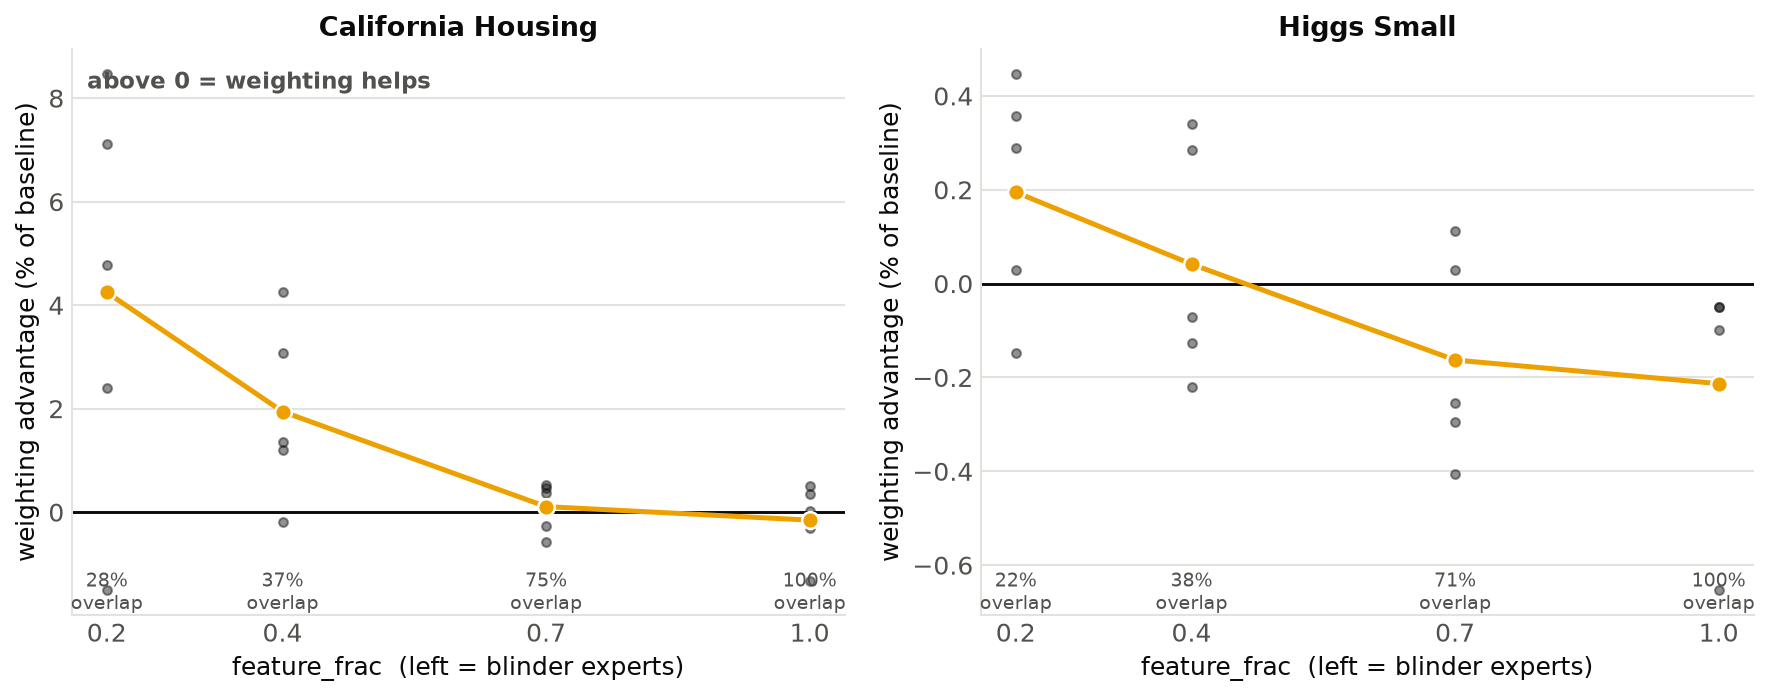

In [10]:
fig, axes = plt.subplots(1, len(KEYS), figsize=(6.0 * len(KEYS), 4.8))
axes = np.atleast_1d(axes)
for ax, k in zip(axes, KEYS):
    g = GAPS[GAPS.dataset == DATA[k].label].sort_values("feature_frac")
    sign = 1.0 if HIB[k] else -1.0
    per = []
    for fr in g.feature_frac:
        w = R[(R.key == k) & (R.frac == fr)].pivot(index="seed", columns="arm", values="score")
        per.append(list(sign * (w[WEIGHTED] - w[BASE]) / w[BASE].abs() * 100))
    ax.axhline(0, color=INK, lw=1.4, zorder=2)
    ax.plot(g.feature_frac, g["gap %"], color=role_color("conf_dynamic"), lw=2.4,
            marker="o", markersize=8, markeredgecolor="white", markeredgewidth=1.2, zorder=4)
    for fr, vals in zip(g.feature_frac, per):
        ax.scatter([fr] * len(vals), vals, s=18, color=INK, alpha=0.45, zorder=3)
    for fr, ov in zip(g.feature_frac, g.overlap):
        ax.annotate(f"{ov:.0%}\noverlap", (fr, ax.get_ylim()[0]), fontsize=9,
                    color=INK_SECONDARY, ha="center", va="bottom")
    ax.set_xlabel("feature_frac  (left = blinder experts)", fontsize=12)
    ax.set_ylabel("weighting advantage (% of baseline)", fontsize=12)
    ax.set_title(DATA[k].label, fontweight="bold")
    ax.set_xticks(FRACS)
    _strip_axes(ax)
axes[0].text(0.02, 0.96, "above 0 = weighting helps", transform=axes[0].transAxes,
             fontsize=11, fontweight="bold", color=INK_SECONDARY, va="top")
plt.tight_layout()
if not SUBSAMPLE:
    os.makedirs(FIG_DIR, exist_ok=True)
    fig.savefig(os.path.join(FIG_DIR, "feature_frac_sweep.pdf"), dpi=200)
    fig.savefig(os.path.join(FIG_DIR, "feature_frac_sweep.png"), dpi=200)
plt.show()

## 8. Did the weights commit more when experts were blinder?

A secondary check. If blindness is real and detectable, the learned weights should spread out more
at low `feature_frac` — lower entropy. If entropy stays pinned near 1.0 at every frac, the
confidence head never found a signal to act on, whatever the geometry says.

In [11]:
ent = R[R.arm == WEIGHTED].groupby(["key", "frac"])["entropy"].mean().unstack("frac")
ent.index = [DATA[k].label for k in ent.index]
print("Learned weight entropy (1.0 = uniform). Lower = the model committed to some experts.")
show(ent, {fr: "{:.4f}" for fr in FRACS})

Learned weight entropy (1.0 = uniform). Lower = the model committed to some experts.


frac,0.200000,0.400000,0.700000,1.000000
California Housing,0.8263,0.9105,0.9750,0.9894
Higgs Small,0.9126,0.9681,0.9858,0.9918


## 9. Verdict — applying the pre-registered rule

In [12]:
sep = "=" * 92
print(sep); print("VERDICT -- does weighting start to matter once experts are genuinely blind?"); print(sep)

low = [fr for fr in FRACS if fr <= 0.4]
wins_low = {}
for k in KEYS:
    g = GAPS[(GAPS.dataset == DATA[k].label) & (GAPS.feature_frac.isin(low))]
    wins_low[DATA[k].label] = bool((g.verdict == "weighting better").all()) and len(g) > 0

print("\nAt feature_frac <= 0.4 (genuinely blind experts):")
for k in KEYS:
    g = GAPS[(GAPS.dataset == DATA[k].label) & (GAPS.feature_frac.isin(low))]
    for _, r in g.iterrows():
        print(f"   {r.dataset:20s} frac {r.feature_frac:.1f} ({r.overlap:.0%} overlap): "
              f"{r['gap %']:+.2f}%  p={r.p:.3f}  -> {r.verdict}")

print("\nAt feature_frac = 0.7 (the project default):")
for k in KEYS:
    g = GAPS[(GAPS.dataset == DATA[k].label) & (GAPS.feature_frac == 0.7)]
    for _, r in g.iterrows():
        print(f"   {r.dataset:20s} {r['gap %']:+.2f}%  p={r.p:.3f}  -> {r.verdict}")

print("\nTrend (negative rho = the gap grows as experts go blind):")
for ds, r in TREND.iterrows():
    print(f"   {ds:20s} rho={r['Spearman rho (frac vs gap)']:+.3f}  p={r.p:.4f}  -> {r.reading}")

all_low_win = all(wins_low.values())
trend_ok = bool((TREND["Spearman rho (frac vs gap)"] < 0).all() and (TREND["p"] < 0.05).all())
any_win = bool((GAPS.verdict == "weighting better").any())

print()
if all_low_win and trend_ok:
    print("-> THE MECHANISM IS REAL, AND feature_frac=0.7 IS OUTSIDE ITS REGIME.")
    print("   Weighting helps when experts are genuinely blind. Our default simply does not")
    print("   produce blind experts, which is why notebooks 17/18 found nothing.")
elif not any_win:
    print("-> WEIGHTING DOES NOT HELP AT ANY LEVEL OF BLINDNESS.")
    print("   Notebook 18's null is not configuration-specific: even with experts sharing only")
    print("   ~25% of their columns, weighting them beats weighting them equally nowhere.")
    print("   The likely reason is that joint end-to-end training already neutralises a weak")
    print("   expert in its WEIGHTS, so down-weighting it afterwards is redundant.")
else:
    print("-> PARTIAL: weighting helps in some (dataset, frac) cells but the pre-registered")
    print("   rule is not met. Read the per-cell table and the trend together, and do not")
    print("   claim a general result from it.")
if SUBSAMPLE:
    print("\nSMOKE TEST MODE -- these verdicts are meaningless, the pipeline check is what matters.")
print(sep)

VERDICT -- does weighting start to matter once experts are genuinely blind?

At feature_frac <= 0.4 (genuinely blind experts):
   California Housing   frac 0.2 (28% overlap): +4.25%  p=0.076  -> no real difference
   California Housing   frac 0.4 (37% overlap): +1.94%  p=0.068  -> no real difference
   Higgs Small          frac 0.2 (22% overlap): +0.19%  p=0.155  -> no real difference
   Higgs Small          frac 0.4 (38% overlap): +0.04%  p=0.735  -> no real difference

At feature_frac = 0.7 (the project default):
   California Housing   +0.11%  p=0.643  -> no real difference
   Higgs Small          -0.16%  p=0.176  -> no real difference

Trend (negative rho = the gap grows as experts go blind):
   California Housing   rho=-0.582  p=0.0071  -> gap GROWS as experts go blind
   Higgs Small          rho=-0.520  p=0.0189  -> gap GROWS as experts go blind

-> WEIGHTING DOES NOT HELP AT ANY LEVEL OF BLINDNESS.
   Notebook 18's null is not configuration-specific: even with experts sharing on

## 10. Notes

* **The gap is the measurement, not the scores.** Lower `feature_frac` is expected to hurt both
  arms; notebook 16 already showed bagging is not load-bearing for diversity. Only the
  *difference between the arms at a fixed frac* answers this question.
* **`frac=1.0` is the zero-blindness control**: every expert sees every column, so the experts
  differ only by initialisation and dropout. If weighting ever helps, it should help least here.
* **Both arms share bit-identical experts and column subsets** at a given (dataset, frac, seed),
  so the pairing is exact.
* **A null here is a stronger result than notebooks 17/18.** Those showed weighting does not help
  at one configuration. If the gap is flat across a 28%-to-100% overlap range, the conclusion is
  that it does not help *because of how the ensemble is trained*, not because of how it is bagged
  — which is a claim about the architecture rather than about one hyperparameter.